In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from scipy.io import wavfile
import scipy.io
from sklearn import svm


d = os.listdir()
if "Model_1" in d:
    os.chdir("Model_1") # Just some logic to be able to re-run cell in Jupyter notebook, as multiple runs changes the cwd.

print("Imports complete")
print("Running from: " + os.getcwd())
print("Please place dataset *one level up* from this folder.")
os.chdir("..")

Imports complete
Running from: C:\Users\leona\Documents\Krona\Hoost 2026\AI and Machine Learning\Project\Model_1
Please place dataset *one level up* from this folder.


In [2]:
train_path = r"\IDMT-ISA-ELECTRIC-ENGINE\train_cut/"
t_path_good = os.getcwd() + train_path + "engine1_good"
t_path_broken = os.getcwd() + train_path + "engine2_broken"
t_path_heavy = os.getcwd() + train_path + "engine3_heavyload"

good_samples_count = len(os.listdir(t_path_good))
broken_samples_count = len(os.listdir(t_path_broken))
heavy_samples_count = len(os.listdir(t_path_heavy))

rate, test = wavfile.read(os.path.join(t_path_good, os.listdir(t_path_good)[0]))
good_n = test.shape[0] # Each WAV file happens to be same amount of samples, so no need to test all of them.

train_good = np.zeros((good_samples_count, good_n))
train_broken = np.zeros((broken_samples_count, good_n))
train_heavy = np.zeros((heavy_samples_count, good_n))

print("Reading train_cut_good...")
for idx, e in enumerate(os.listdir(t_path_good)):
    _, data = wavfile.read(os.path.join(t_path_good, e))
    train_good[idx] = data
    
print("Reading train_cut_bad...")
for idx, e in enumerate(os.listdir(t_path_broken)):
    _, data = wavfile.read(os.path.join(t_path_broken, e))
    train_broken[idx] = data
    
print("Reading train_cut_heavy...")
for idx, e in enumerate(os.listdir(t_path_heavy)):
    _, data = wavfile.read(os.path.join(t_path_heavy, e))
    train_heavy[idx] = data

print("Done.")

Reading train_cut_good...
Reading train_cut_bad...
Reading train_cut_heavy...
Done.


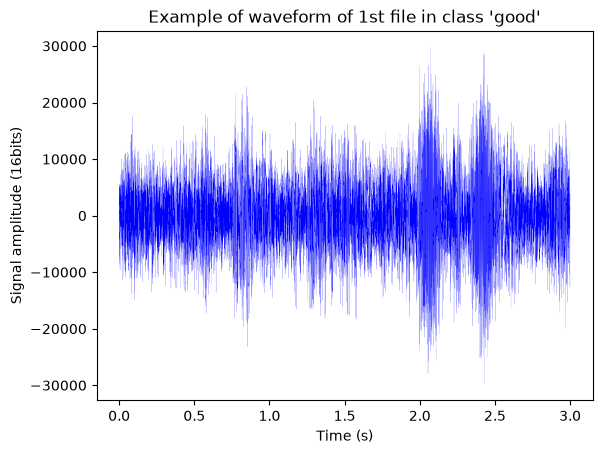

In [3]:
t = np.arange(0.0, 3.0, 1/rate)

plt.figure()
plt.plot(t, train_good[0], lw=0.075, color="blue")
plt.xlabel("Time (s)")
plt.ylabel("Signal amplitude (16bits)")
plt.title("Example of waveform of 1st file in class 'good'")
plt.show()

In [22]:
# Good vs broken first; first 669 are 1's, rest are 0.

a = np.ones(good_samples_count)
b = np.zeros(broken_samples_count)
target = np.concatenate((a,b))
print("Target shape: " + str(target.shape))

tot = np.concatenate((train_good, train_broken))
binN = 50
inp = np.zeros((good_samples_count+broken_samples_count, binN))
for i in range(good_samples_count+broken_samples_count):
    inp[i] = np.histogram(tot[i], bins=binN)[0]
print("Input shape: " + str(inp.shape))

Target shape: (1334,)
Input shape: (1334, 50)


In [23]:
x_train, x_test, y_train, y_test = train_test_split(inp, target, test_size=0.15, random_state=42)

sc = StandardScaler()
x_train_sc = sc.fit_transform(x_train)
x_test_sc = sc.transform(x_test)

model = svm.SVC(kernel='linear', random_state=42)
model.fit(x_train_sc, y_train)

y_pred = model.predict(x_test_sc)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")

Accuracy: 0.701
